# Paramétrage des règles V2

Les règles de l'espace V2 (EvoPi), **écrites dans ce notebook** (une cellule par règle) pour pouvoir les modifier, en
ajouter ou en retirer sans toucher à evomol. Comme le notebook de V1 (`teste_newmut_V1/parametrage_regles.ipynb`),
pour les règles seulement (pas encore les mutations) :
1. passer une liste de molécules **bonnes** et une liste de **mauvaises** dans les règles : faux positifs (bonne
   refusée), faux négatifs (mauvaise acceptée), et règle par règle ce qu'elle refuse ;
2. tirer des molécules dans les marches newmut ou dans ChEMBL (molécules entières ou systèmes π) et voir ce que
   les règles en disent ;
3. voir sur les dessins et dans la matrice **quelle partie de la molécule déclenche quelle règle** (une couleur par
   règle) ;
4. mesurer le temps des règles.

**États des atomes.** Chaque atome lourd a un état lu sur la matrice : `t` s'il porte une triple liaison, `d` une
double, `s` que des simples (l'ordre de liaison le plus haut, pas l'hybridation). C, N, P : s, d, t ; O, S, B : s, d ;
halogènes : s.

| V2 | règle | en V1 |
|---|---|---|
| R1 | valence (P 3, S 2) | R1 (S jusqu'à 6) |
| R2 | tout atome `s` a au moins un voisin `d` ou `t` | remplace R2a, R2b, R2c (liaisons entre atomes `s`) |
| R3a | un C porte au plus une double liaison (pas d'allène) | R3 |
| R3b | un C `s` porte au moins 2 H | R5 |
| R3c | pas de radical (ni de charge) : pas vérifiée | — |
| R4 | pas de tête de pont dans deux cycles de moins de 12 atomes | R4 (limite 8) |

Les outils sont dans `regles_V2.py` (aucune règle dedans ; il reprend ceux de V1). Après avoir modifié une règle,
relancer sa cellule **et la cellule `RULES`**, puis les cellules de résultats.

In [36]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT / "teste_newmut_V2" / "Rule_V2"))

from itertools import combinations

import numpy as np
from IPython.display import display

import regles_V2 as rv              # teste_newmut_V2/Rule_V2/regles_V2.py
from regles_V2 import Violation     # Violation(règle, atomes, message)

## Paramètres

Les règles lisent ces variables : après un changement ici, relancer seulement les cellules de résultats.

In [37]:
VALENCES = {                  # valence max par élément (un élément absent : 4) ; P et S jamais hypervalents
    "B": 3, "C": 4, "N": 3, "O": 2, "F": 1, "Cl": 1, "Br": 1, "P": 3, "S": 2,
}
# éléments soumis à R2 (atome s : au moins un voisin d ou t) ; tous les atomes lourds d'EvoPi
TAGGED = ("C", "N", "O", "B", "S", "P", "F", "Cl", "Br")
BRIDGE_RING = 12              # R4 : cycles de moins de BRIDGE_RING atomes

## Règles

Chaque règle est une fonction `R(g)` qui renvoie la liste de ses violations `Violation(nom, atomes, message)`. Les
`atomes` sont ceux qui seront coloriés sur les dessins et dans la matrice (et les liaisons entre eux).

`g` (`rv.GrapheV2`) est la molécule lue sur la matrice (H implicites). Pour aller vite, les règles lisent des
tableaux numpy calculés une fois par molécule (un élément par atome) :
- `g.elements` : élément ; `g.tags` : état `"s"`, `"d"` ou `"t"` ; `g.is_dt` : atome `d` ou `t` ;
- `g.deg` : nombre de voisins lourds ; `g.bond_sums` : somme de la ligne hors diagonale ; `g.max_order` : ordre le
  plus haut ; `g.n_double` : nombre de doubles liaisons ;
- `g.orders` : matrice des ordres (diagonale à 0) ; `g.adjacency` : 1 si deux atomes sont liés.

Et, comme en V1 : `g.types`, `g.n`, `g.order[i][j]`, `g.adj[i]`, `g.bonds`, `g.in_ring(a, b)`, `g.bridges`,
`g.rings` (plus petit cycle passant par chaque liaison, liste ordonnée d'atomes, sans doublon ; calculé à la
première demande), et `g.cyclomatic` (nombre de cycles indépendants), `g.mol` (molécule RDKit, ou `None` si le
graphe vient d'une matrice seule). `rv.atoms_text(g, atomes)` écrit « C1 s, O4 s ».

### Outils communs aux règles

In [38]:
def valence_max(g):
    return np.array([VALENCES.get(element, 4) for element in g.types], dtype=np.int64)


def is_element(g, elements):
    """Atomes dont l'élément est dans elements (plus rapide que np.isin sur de petites molécules)."""
    return np.fromiter((element in elements for element in g.types), dtype=bool, count=g.n)

### R1 : valence

La somme d'une ligne de la matrice (hors diagonale) ne dépasse pas la valence max de l'élément (`VALENCES` : P 3,
S 2, pas d'hypervalence).

In [39]:
def R1(g):
    vmax = valence_max(g)
    return [Violation("R1", (int(i),), f"{g.types[i]}{i} porte {g.bond_sums[i]} liaisons pour une valence max de {vmax[i]}")
            for i in np.flatnonzero(g.bond_sums > vmax)]

### R2 : tout atome `s` a au moins un voisin `d` ou `t`

Un atome `s` (de `TAGGED`) est toujours accroché à un atome `d` ou `t` : pas de chaîne saturée, pas de CH₃ sur un
O ou un N `s`. Pas d'exception de cycle (anisole, N,N-diméthylaniline, EDOT, indane sont refusés) ; un atome seul
(CH₄), sans voisin, est refusé. Calcul : nombre de voisins `d` ou `t` de chaque atome = `adjacency @ is_dt`.

In [40]:
def R2(g):
    dt_neighbours = g.adjacency @ g.is_dt
    found = []
    for i in np.flatnonzero((g.tags == "s") & is_element(g, TAGGED) & (dt_neighbours == 0)):
        voisins = rv.atoms_text(g, g.adj[i]) or "aucun"
        found.append(Violation("R2", (int(i),), f"{g.types[i]}{i} (s) n'a aucun voisin d ou t (voisins : {voisins})"))
    return found

### R3 : états permis (R3a, R3b, R3c)

#### R3a : un carbone porte au plus une double liaison (ex-R3 de V1)

Pas d'allène (`C=C=C`) : il n'étend pas la conjugaison.

In [41]:
def R3a(g):
    return [Violation("R3a", (int(i), *(j for j in g.adj[i] if g.order[i][j] == 2)),
                      f"C{i} porte {g.n_double[i]} doubles liaisons (allène)")
            for i in np.flatnonzero((g.elements == "C") & (g.n_double > 1))]

#### R3b : un carbone `s` porte au moins 2 H (ex-R5 de V1)

Un C `s` a au plus 2 voisins lourds : CH₄, CH₃, CH₂ seulement (ni CH ramifié, ni carbone quaternaire).

In [42]:
def R3b(g):
    return [Violation("R3b", (int(i),), f"C{i} est un carbone s qui porte {g.deg[i]} atomes lourds "
                                        f"({max(4 - g.deg[i], 0)} H, au moins 2 demandés)")
            for i in np.flatnonzero((g.elements == "C") & (g.tags == "s") & (g.deg > 2))]

#### R3c : pas de radical (ni d'atome chargé)

**Pas vérifiée** (commentée dans `RULES`) : elle ne peut pas être cassée à partir d'une matrice. La fonction reste
ici pour mémoire.

Avec une seule valence par élément et des H implicites, une matrice ne peut pas porter de radical : la règle lit
les électrons non appariés et les charges de la molécule RDKit (`g.mol`), quand le graphe vient d'un SMILES. Sur une
matrice seule (`g.mol` vaut `None`), elle ne trouve rien.

In [43]:
def R3c(g):
    if g.mol is None:
        return []
    found = []
    for atom in [a for a in g.mol.GetAtoms() if a.GetNumRadicalElectrons() or a.GetFormalCharge()]:
        radicals, charge, i = atom.GetNumRadicalElectrons(), atom.GetFormalCharge(), atom.GetIdx()
        what = ", ".join(t for t in (f"{radicals} électron(s) non apparié(s)" if radicals else "",
                                     f"charge {charge:+d}" if charge else "") if t)
        found.append(Violation("R3c", (i,), f"{g.types[i]}{i} : {what}"))
    return found

### R4 : pas de tête de pont dans les cycles de moins de `BRIDGE_RING` atomes

Deux cycles qui partagent plus d'une liaison (plus de 2 atomes, ou 2 atomes non liés) sont pontés ; les atomes
partagés aux extrémités sont les têtes de pont. Entre ces deux têtes de pont, on a alors au moins trois chemins (le
chemin partagé et le reste de chacun des deux cycles). Le pont est jugé sur **le plus grand cycle qui passe par
les deux têtes de pont, cherché dans toute la molécule** (les deux plus longs chemins sans atome commun entre les
têtes de pont, mis bout à bout) : refusé s'il a moins de `BRIDGE_RING` atomes. Norbornène (cycles 5, 5, 6) refusé ;
un [7]métacyclophane (cycles 6, 10, 12) permis ; un [8]paracyclophane (6, 12, 12) permis. Avant le 2026-10-23, les
chemins étaient cherchés seulement dans les deux cycles du pont : deux cycles de 11 atomes pontés étaient refusés
même quand le reste de la molécule ferme un cycle plus grand par les têtes de pont.

Les cycles de départ sont **tous** les plus petits cycles de chaque liaison, de moins de `BRIDGE_RING` atomes : quand
une liaison est dans plusieurs plus petits cycles de même taille, tous sont gardés. `g.rings` (V1) n'en garde qu'un,
choisi selon la numérotation des atomes : jusqu'au 2026-10-23, R4 ne voyait pas certains ponts (petites cages) et le
verdict d'une même molécule changeait avec la numérotation (section « Problèmes de R4 »). Seules les paires où les
deux cycles ont moins de `BRIDGE_RING` atomes sont regardées (sinon le plus grand cycle a déjà au moins
`BRIDGE_RING` atomes).

Pour aller vite :
- une tête de pont a au moins 3 voisins de cycle (jamais un O, un S, un halogène, un atome `t`…) : les cycles ne
  sont cherchés que dans les systèmes de cycles (atomes reliés par des liaisons de cycle) qui ont au moins deux
  cycles ; les cycles seuls et les cycles reliés par une chaîne (biphényle) ne sont pas regardés ;
- le plus grand cycle est calculé une fois par paire de têtes de pont ;
- dès que les deux chemins ont ensemble `BRIDGE_RING` - 2 atomes intérieurs (`BRIDGE_RING` atomes avec les têtes de
  pont), on ne les allonge plus : on vérifie seulement que le cycle peut se fermer (un parcours, ou un flot de deux
  chemins sans atome commun).

Sans au moins deux cycles indépendants, rien à chercher.


In [ ]:
from collections import deque


def bridge_paths(ring, shared):
    """Têtes de pont (x, y) : les atomes partagés qui ont un voisin non partagé dans le cycle (ring : liste
    ordonnée), et les deux chemins du cycle entre x et y (atomes intérieurs, sans x ni y)."""
    n = len(ring)
    ends = [k for k in range(n) if ring[k] in shared
            and (ring[k - 1] not in shared or ring[(k + 1) % n] not in shared)]
    if len(ends) != 2:
        return None
    k1, k2 = ends
    return (ring[k1], ring[k2]), (tuple(ring[k1 + 1:k2]), tuple(ring[k2 + 1:] + ring[:k1]))


def ring_systems(g):
    """Voisins de chaque atome par une liaison de cycle (ring_adj), et systèmes de cycles (atomes reliés par des
    liaisons de cycle) qui ont au moins deux cycles. Une tête de pont a au moins 3 voisins de cycle : les cycles
    seuls et les cycles reliés par une chaîne (biphényle) ne peuvent pas être pontés et ne sont pas regardés."""
    ring_adj = [[v for v in g.adj[u] if (min(u, v), max(u, v)) not in g.bridges] for u in range(g.n)]
    seen = [False] * g.n
    systems = []
    for start in range(g.n):
        if seen[start] or not ring_adj[start]:
            continue
        seen[start] = True
        stack, atoms = [start], []
        while stack:
            u = stack.pop()
            atoms.append(u)
            for v in ring_adj[u]:
                if not seen[v]:
                    seen[v] = True
                    stack.append(v)
        n_bonds = sum(len(ring_adj[a]) for a in atoms) // 2
        if n_bonds - len(atoms) + 1 >= 2:
            systems.append(atoms)
    return ring_adj, systems


def smallest_rings(ring_adj, atoms, limit):
    """Plus petits cycles de moins de limit atomes de chaque liaison du système (atoms), liste ordonnée d'atomes,
    sans doublon. En cas d'égalité, **tous** les cycles de même taille sont gardés (g.rings n'en garde qu'un, choisi
    selon la numérotation des atomes) : pour chaque liaison (a, b), tous les plus courts chemins de a à b sans
    cette liaison (recherche en largeur par couches, arrêtée à limit - 1 atomes)."""
    rings = {}
    for a in atoms:
        for b in ring_adj[a]:
            if b < a:
                continue
            parents = {a: []}   # atome -> atomes de la couche précédente qui y mènent
            layer, depth = [a], 0
            while layer and b not in parents and depth < limit - 2:
                nxt = {}
                for u in layer:
                    for v in ring_adj[u]:
                        if (u == a and v == b) or v in parents:
                            continue
                        nxt.setdefault(v, []).append(u)
                parents.update(nxt)
                layer, depth = list(nxt), depth + 1
            if b not in parents:
                continue
            stack = [[b]]
            while stack:
                path = stack.pop()
                if path[-1] == a:
                    rings.setdefault(frozenset(path), path)
                    continue
                stack.extend(path + [u] for u in parents[path[-1]])
    return list(rings.values())


def r4_rings(g):
    """Cycles de départ de R4 (tous les systèmes de cycles mis bout à bout)."""
    ring_adj, systems = ring_systems(g)
    return [ring for atoms in systems for ring in smallest_rings(ring_adj, atoms, BRIDGE_RING)]


def reaches(adj, u, y, used):
    """Un chemin de u à y sans passer par les atomes de used."""
    seen = set(used)
    seen.add(u)
    stack = [u]
    while stack:
        a = stack.pop()
        for w in adj[a]:
            if w == y:
                return True
            if w not in seen:
                seen.add(w)
                stack.append(w)
    return False


def two_paths_to(adj, sources, y, blocked):
    """Deux chemins sans atome commun (sauf y), un depuis chacune des deux sources jusqu'à y, sans passer par
    blocked ni par les sources : flot de 2 avec une capacité de 1 par atome (chaque atome dédoublé en entrée et
    sortie)."""
    capacity, out = {}, {}

    def arc(a, b):
        capacity[(a, b)] = capacity.get((a, b), 0) + 1
        capacity.setdefault((b, a), 0)
        out.setdefault(a, []).append(b)
        out.setdefault(b, []).append(a)

    source, sink = ("S",), (y, "in")
    for s in sources:
        arc(source, (s, "out"))
    for v in range(len(adj)):
        if v in blocked or v == y:
            continue
        if v not in sources:
            arc((v, "in"), (v, "out"))
        for w in adj[v]:
            if w not in blocked and w not in sources:
                arc((v, "out"), (w, "in"))
    for _ in range(2):
        previous = {source: None}
        queue = deque([source])
        while queue and sink not in previous:
            a = queue.popleft()
            for b in out.get(a, ()):
                if b not in previous and capacity[(a, b)] > 0:
                    previous[b] = a
                    queue.append(b)
        if sink not in previous:
            return False
        b = sink
        while previous[b] is not None:
            a = previous[b]
            capacity[(a, b)] -= 1
            capacity[(b, a)] += 1
            b = a
    return True


def longest_cycle(adj, x, y, cap):
    """Nombre d'atomes du plus grand cycle passant par x et y (deux chemins de x à y sans atome commun), plafonné à
    cap : dès que les deux chemins ont ensemble cap - 2 atomes intérieurs (cap atomes avec x et y), on ne les
    allonge plus, on vérifie seulement que le cycle peut se fermer. adj : voisins de cycle de chaque atome."""
    need = cap - 2
    best = 0

    def second(u, used, k1, k2):
        # second chemin parti de x, arrivé en u avec k2 atomes intérieurs ; le premier chemin en a k1
        nonlocal best
        if k1 + k2 >= need:
            return reaches(adj, u, y, used)
        for w in adj[u]:
            if w == y:
                if k1 or k2:          # pas deux fois la liaison x-y
                    best = max(best, k1 + k2 + 2)
            elif w not in used:
                used.add(w)
                found = second(w, used, k1, k2 + 1)
                used.discard(w)
                if found:
                    return True
        return False

    def first(u, used, interior):
        # premier chemin parti de x, arrivé en u (interior : ses atomes intérieurs)
        if len(interior) >= need:
            return two_paths_to(adj, (x, u), y, set(interior[:-1]))
        for w in adj[u]:
            if w == y:
                if second(x, set(used), len(interior), 0):
                    return True
            elif w not in used:
                used.add(w)
                interior.append(w)
                found = first(w, used, interior)
                interior.pop()
                used.discard(w)
                if found:
                    return True
        return False

    return cap if first(x, {x, y}, []) else best


def R4(g):
    if g.cyclomatic < 2:
        return []
    ring_adj, systems = ring_systems(g)
    found = []
    for atoms in systems:
        small = smallest_rings(ring_adj, atoms, BRIDGE_RING)
        small_sets = [set(ring) for ring in small]
        largest_of = {}   # plus grand cycle par chaque paire de têtes de pont
        for i, j in combinations(range(len(small)), 2):
            shared = [x for x in small[i] if x in small_sets[j]]
            if not (len(shared) > 2 or (len(shared) == 2 and not g.order[shared[0]][shared[1]])):
                continue
            found_i, found_j = bridge_paths(small[i], set(shared)), bridge_paths(small[j], set(shared))
            largest = None
            if found_i is not None and found_j is not None and set(found_i[0]) == set(found_j[0]):
                heads = tuple(sorted(found_i[0]))
                if heads not in largest_of:
                    largest_of[heads] = longest_cycle(ring_adj, *heads, BRIDGE_RING)
                largest = largest_of[heads]
                if largest >= BRIDGE_RING:
                    continue
            taille = (f"plus grand cycle par les têtes de pont : {largest} atomes" if largest
                      else "têtes de pont introuvables")
            found.append(Violation("R4", tuple(shared), f"cycles de {len(small[i])} et {len(small[j])} atomes pontés "
                                                         f"({len(shared)} atomes partagés ; {taille})"))
    return found

### Règles utilisées

`RULES` : les règles appliquées, dans l'ordre (la couleur de chaque règle suit cet ordre). Pour ajouter une règle,
écrire sa fonction dans une nouvelle cellule et l'ajouter ici ; pour en retirer une, la commenter.

`COMPTE_SEPARE` : servira aux mutations (une mutation est permise si elle ne crée aucune nouvelle violation ; les
règles listées ici sont comptées chacune à part, les autres ensemble).

In [45]:
RULES = {
    "R1": R1,
    "R2": R2,
    "R3a": R3a,
    "R3b": R3b,
    #"R3c": R3c,      # impossible à casser à partir d'une matrice : pas vérifiée
    "R4": R4,
}
COMPTE_SEPARE = ["R1"]

REGLES = rv.Regles(RULES, COMPTE_SEPARE)
display(REGLES.legend())

## Molécules bonnes et mauvaises

Un SMILES, ou `(SMILES, commentaire)`. Le commentaire donne les règles attendues. `AUTRES` : molécules à classer
(rien d'attendu).

In [46]:
"""
BONNES = [
    ("c1ccccc1", "benzène"),
    ("c1ccc2ccccc2c1", "naphtalène"),
    ("c1ccc2cccc2cc1", "azulène"),
    ("c1ccncc1", "pyridine"),
    ("c1cc[nH]c1", "pyrrole"),
    ("c1ccoc1", "furane"),
    ("c1ccsc1", "thiophène"),
    ("c1ccc2[nH]ccc2c1", "indole"),
    ("Cc1ccccc1", "toluène : CH3 sur un C d"),
    ("Oc1ccccc1", "phénol"),
    ("Fc1ccccc1", "fluorobenzène"),
    ("Sc1ccccc1", "thiophénol (S valence 2)"),
    ("O=Cc1ccccc1", "benzaldéhyde"),
    ("N#Cc1ccccc1", "benzonitrile"),
    ("O=C1C=CC(=O)C=C1", "benzoquinone"),
    ("C=CC", "propène"),
    ("CC#C", "propyne : CH3 sur un C t"),
    ("CC(C)=C", "isobutène"),
    ("C=Cc1ccccc1", "styrène"),
    ("C1=CCC=C1", "cyclopentadiène : CH2 entre deux C d"),
    ("C1Cc2ccccc2C=C1", "1,2-dihydronaphtalène"),
    ("C1Cc2cccc3cccc1c23", "acénaphtène : chaque CH2 touche un C d"),
    ("c1ccc(cc1)Nc1ccccc1", "diphénylamine"),
    ("c1ccc(cc1)P(c1ccccc1)c1ccccc1", "triphénylphosphine (P valence 3)"),
    ("C1=CC=CC=CC=CC=CC=CC=CC=C1", "[18]annulène"),
    ("c1cc2ccc1C=CC=CC=CC=C2", "[8]paracyclophane-tétraène : cycles 6, 12, 12 (R4 permis)"),
    ("c1cc2cc(c1)C=CC=CC=CC2", "[7]métacyclophane-triène : cycles 6, 10, 12 (R4 permis)"),
]
#MAUVAISES = [
    ("C", "méthane : atome seul (R2)"),
    ("CC", "éthane (R2)"),
    ("CCc1ccccc1", "éthylbenzène : CH3 sur un CH2 (R2)"),
    ("COc1ccccc1", "anisole : CH3 sur un O s (R2)"),
    ("CN(C)c1ccccc1", "N,N-diméthylaniline (R2)"),
    ("OO", "peroxyde d'hydrogène (R2)"),
    ("FCc1ccccc1", "fluorure de benzyle : F sur un CH2 (R2)"),
    ("C1Cc2ccccc2C1", "indane : CH2 du milieu (R2)"),
    ("C1CCCCC1", "cyclohexane (R2)"),
    ("C1COc2cscc2O1", "EDOT : CH2–CH2 (R2)"),
    ("C=C=C", "allène (R3a)"),
    ("CC(C)c1ccccc1", "isopropylbenzène (R2, R3b)"),
    ("CC(C)(C)c1ccccc1", "tert-butylbenzène (R2, R3b)"),
    ("C[n+]1ccccc1", "N-méthylpyridinium : chargé (R1)"),
    ("ClP(Cl)(Cl)(Cl)Cl", "PCl5 : P hypervalent (R1, R2)"),
    ("CS(=O)(=O)c1ccccc1", "méthylphénylsulfone : S hypervalent (R1)"),
    ("C1=CC2C=CC1C2", "norbornadiène (R2, R3b, R4)"),
    ("C1=CC2C=CC1C=C2", "barrelène (R3b, R4)"),
    ("c1cc2ccc1C=CC=CC=CC2", "[7]paracyclophane-triène : cycles 6, 11, 11 (R4)"),
    ("c1cc2cc(c1)C=CC=CC=C2", "[6]métacyclophane-triène : cycles 6, 9, 11 (R4)"),
]
"""
AUTRES = [
"""
    "C1=CC2=CC3=CC=C([N-]3)C=C4C=CC(=N4)C=C5C=CC(=N5)C=C1[N-]2",  # porphyrine
    "NNc1ccccc1",                 # phénylhydrazine (N–N)
    "CON=C",                      # éther d'oxime (C–O)
    "C1=CNNC=C1",                 # 1,2-dihydropyridazine
    "C1=CCNN1",                   # pyrazoline
    "O=S(=O)(c1ccccc1)c1ccccc1",  # diphénylsulfone
    "COc1ccccc1",                 # anisole (CH3–O)
    "C1Oc2cscc2OC1",             # ProDOT
    "C1=CNNNC=C1",                # 
    "C1=CNCNC=C1",   
    "C1=CNNCC=C1",             # 
    "C1=CCNCC=C1",             # 
    "OCc1ccccc1",                 # alcool benzylique (Cs–OH)
    "NCc1ccccc1",                 # benzylamine (Cs–NH2)
    "CNC",                        # diméthylamine (NHR–Cs)
    "CN(C)c1ccccc1",              # N,N-diméthylaniline (R2N–Cs)
    "C1CCOC1",                    # THF
    "C1Oc2ccccc2OC1",             # benzodioxane (O reliés au benzène)
    "C1#CC=CC=C1",                # benzyne : ChangeBondMG 2 → 3 sur le benzène
    "C1=C=CC=CC=1",               # ChangeBondMG 1 → 2 sur le benzène (R3a)
    # refusées par R4b seule (R4b désactivée par défaut depuis le 2026-10-15) ; teste/resultats/lot.csv
    "C1=CC=CC=CC=CC=CC=C1",       # [12]annulène (R4b : angle)
    "c1cc2ccc1-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc-2cc1",  # [5]CPP (R4b : angle)
    "c1cc2ccc1-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc-2cc1",  # [6]CPP (R4b : angle)
    "c1cc2ccc1-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc-2cc1",  # [7]CPP (R4b : angle)
    "c1cc2ccc1-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc(cc1)-c1ccc-2cc1",  # [8]CPP (R4b : angle)
    "c1c#cc#cc#cc#cc#cc#cc#cc#cc#1",  # cyclo[18]carbone (R4b : angle)
    "c1cc2ccc1CCc1ccc(cc1)CC2",   # [2.2]paracyclophane (R4b : carbone s)
    "C1COCCOCCOCCOCCOCCO1",       # 18-couronne-6 (R4b : carbone s)
    "C=C1C#CN2OC3OC(=C4C3=C42)C2=NC2=C1O",  # mutation ChangeBondMG (R4b : angle)
    "C=C1C#CN2OC3OC(=C4C3=C42)C2=NC2=C1OC",  # mutation ChangeBondMG (R4b : angle)
    "C=c1nc2c3ccc([nH]c1=C1C(O)C=NC(=N)C12)CC=C3",  # mutation ChangeBondMG (R4b : angle)
    "C1=CCC=CCOCC=C1",            # mutation ChangeBondMG (R4b : carbone s)
    "C1=CC2=CC(O1)C1=COC1=CC1CC=C1OC2",  # mutation ChangeBondMG (R4b : carbone s)
    "C=C1N=CC2C3=NC4=CC=CCC(=C4)NC1=C2C(O)C=N3",  # mutation ChangeBondMG (R4b : carbone s)
    "C=CC1=COCC1",
    "C=CC1=CNCC1",
    "c1cc[nH][nH][nH][nH]c1",
    "c2ccc1c[nH][nH][nH][nH][nH]c1cc2",
    "c2ccc(NNNc1ccccc1)cc2",
    "c2ccc(NNNNc1ccccc1)cc2",
    "C=C/C=CC=CNNNC/C=CC=C/C",
    "C=C/C=CC=CNNN/C=C/C=CC=C",
    "C2=CC1C=Cc3cc1ccc23",
    "C1=CC2C=CC3=C1C=CC2C=C3",
"""
    "C2CC1CCCC1C2",
]


## GÉNÉRER : molécules tirées dans les marches newmut ou dans ChEMBL

**Marches newmut** (`notebooks/random_walk/results/newmut_walk/`, comme en V1) : une expérience au hasard, une
marche au hasard, puis un pas au hasard (pas 0 exclu). **ChEMBL 34** (`teste_newmut_V2/ChEMBL_comparaison/donnees`) :
`SOURCE_CHEMBL = "molecules"` pour les molécules entières (C, N, O, F, B, sans charge, un seul morceau), `"pi"` pour
les systèmes π qui en ont été extraits (tirés sans tenir compte de leur fréquence).

`GENERER` a le même format que `BONNES` et `MAUVAISES` : `(SMILES, commentaire)`. Même graine : mêmes molécules.
`MAX_ATOMS_GENERER` : seulement les molécules d'au plus ce nombre d'atomes lourds (`None` : toutes). Pour classer
une molécule, copier sa ligne dans `BONNES` ou `MAUVAISES`.

In [47]:
SOURCE_GENERER = "chembl"   # "marches" ou "chembl"
SOURCE_CHEMBL = "pi"        # "pi" ou "molecules"
SEED_GENERER = 0
N_GENERER = 12
MAX_ATOMS_GENERER = None    # None : toutes les tailles

if SOURCE_GENERER == "marches":
    tirage = rv.sample_walks(N_GENERER, seed=SEED_GENERER, max_atoms=MAX_ATOMS_GENERER)
    GENERER = rv.as_list(tirage)
else:
    GENERER = rv.sample_chembl(N_GENERER, seed=SEED_GENERER, source=SOURCE_CHEMBL, max_atoms=MAX_ATOMS_GENERER)
for smiles, comment in GENERER:
    print(f'    ("{smiles}", "{comment}"),')

    ("O=C1NC(=O)N(c2ccccc2O)C(=O)/C1=C\O", "système π · 1 fois · ex. CHEMBL3209210"),
    ("N=C(NNC(=O)O)NNC(=O)O", "système π · 3 fois · ex. CHEMBL21632"),
    ("Nc1n[nH]c2cncc(-c3ccc(NC(=O)Nc4ccccc4)cc3)c12", "système π · 8 fois · ex. CHEMBL256824"),
    ("O=c1oncn1-c1cc(-c2ccccc2)ccc1O", "système π · 1 fois · ex. CHEMBL597732"),
    ("NC(=O)c1ccccc1Nc1cccc(Oc2ccccc2)c1", "système π · 1 fois · ex. CHEMBL549853"),
    ("Nc1cc2[nH]nc(/C=C/c3ccccc3)c2cc1-c1ccncc1", "système π · 1 fois · ex. CHEMBL1090679"),
    ("N=C(N)Nc1ccc2ccccc2c1", "système π · 15 fois · ex. CHEMBL40567"),
    ("O=C(N/N=C/c1ccc(O)c(O)c1)c1c[nH]c2cc(N/N=C/c3ccc(O)c(O)c3)ccc2c1=O", "système π · 3 fois · ex. CHEMBL4440033"),
    ("O=c1c2ccccc2nc(-c2ccccc2)n1/C=C/c1ccccc1", "système π · 3 fois · ex. CHEMBL5278122"),
    ("N/C(=N\C(=O)O)Nc1ccc(-c2ccc(-c3ccc(N/C(N)=N/C(=O)O)cn3)cc2)nc1", "système π · 3 fois · ex. CHEMBL458214"),
    ("c1nc(-c2cnco2)c[nH]1", "système π · 1 fois · ex. CHEMBL4909416"),
    ("Nc1ccc(-n2nnc3c

Ce que les règles du notebook disent de ces molécules (une colonne par règle : nombre de violations), puis leurs
dessins (atomes et liaisons en cause de la couleur de leur règle).

,SMILES,commentaire,verdict,R1,R2,R3a,R3b,R4
0,O=C1NC(=O)N(c2ccccc2O)C(=O)/C1=C\O,système π · 1 fois · ex. CHEMBL3209210,acceptée,0,0,0,0,0
1,N=C(NNC(=O)O)NNC(=O)O,système π · 3 fois · ex. CHEMBL21632,acceptée,0,0,0,0,0
2,Nc1n[nH]c2cncc(-c3ccc(NC(=O)Nc4ccccc4)cc3)c12,système π · 8 fois · ex. CHEMBL256824,acceptée,0,0,0,0,0
3,O=c1oncn1-c1cc(-c2ccccc2)ccc1O,système π · 1 fois · ex. CHEMBL597732,acceptée,0,0,0,0,0
4,NC(=O)c1ccccc1Nc1cccc(Oc2ccccc2)c1,système π · 1 fois · ex. CHEMBL549853,acceptée,0,0,0,0,0
5,Nc1cc2[nH]nc(/C=C/c3ccccc3)c2cc1-c1ccncc1,système π · 1 fois · ex. CHEMBL1090679,acceptée,0,0,0,0,0
6,N=C(N)Nc1ccc2ccccc2c1,système π · 15 fois · ex. CHEMBL40567,acceptée,0,0,0,0,0
7,O=C(N/N=C/c1ccc(O)c(O)c1)c1c[nH]c2cc(N/N=C/c3c...,système π · 3 fois · ex. CHEMBL4440033,acceptée,0,0,0,0,0
8,O=c1c2ccccc2nc(-c2ccccc2)n1/C=C/c1ccccc1,système π · 3 fois · ex. CHEMBL5278122,acceptée,0,0,0,0,0
9,N/C(=N\C(=O)O)Nc1ccc(-c2ccc(-c3ccc(N/C(N)=N/C(...,système π · 3 fois · ex. CHEMBL458214,acceptée,0,0,0,0,0



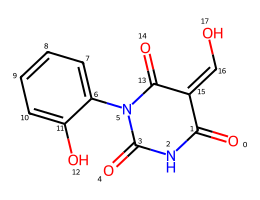
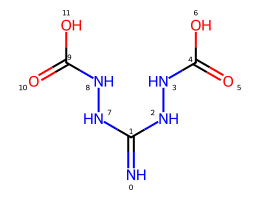
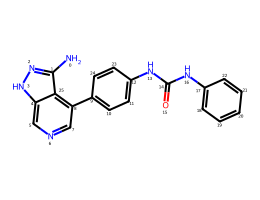
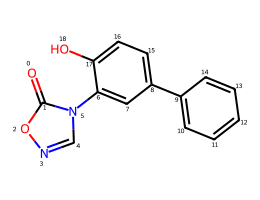
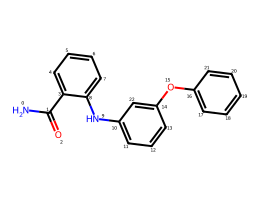
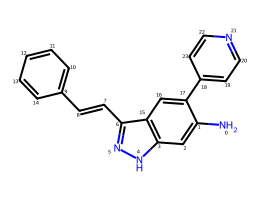
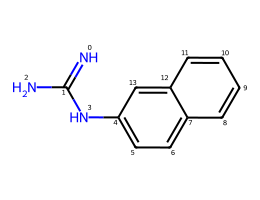
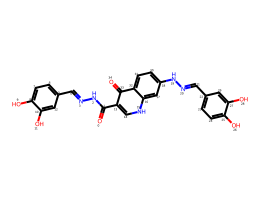
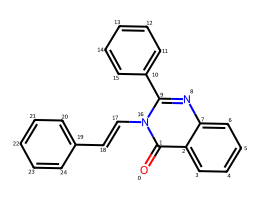
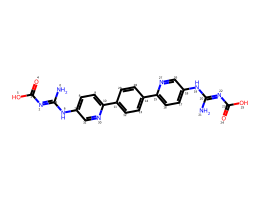
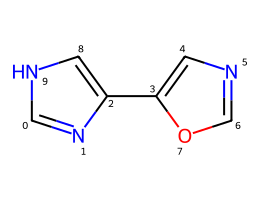
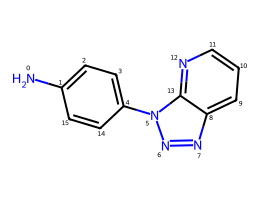

In [48]:
display(rv.inspect(GENERER, REGLES))
display(REGLES.legend())
display(rv.show_items(GENERER, REGLES))

## Problèmes de R4 : dépendance à la numérotation des atomes (réglés le 2026-10-23)

Jusqu'au 2026-10-23, R4 partait de `g.rings`, qui garde **un seul** plus petit cycle par liaison : quand une liaison
est dans plusieurs plus petits cycles de même taille, celui gardé dépend de l'ordre des atomes. Selon la numérotation,
R4 voyait le pont ou non, et la même molécule était refusée ou acceptée. Depuis, R4 garde tous les plus petits cycles
en cas d'égalité, et juge le pont sur le plus grand cycle par les têtes de pont dans toute la molécule.

Cette section reste comme contrôle. `PROBLEMES_R4` : n1c2c3c2c2c3n12 (énumération V1) et les 20 cages des marches
`teste_newmut_V2/Walk_V2/resultats/test_Regle_V2_Bd` dont le verdict changeait avec la numérotation (refusées
maintenant dans toutes les numérotations) ; `REGLES_R4` : les deux molécules des marches du 2026-10-22, acceptées
dans toutes les numérotations. Pour chacune : R4 telle qu'evomol lit le SMILES, le nombre de numérotations au hasard
(`N_NUMEROTATIONS`, graine `SEED_NUMEROTATIONS`) où R4 refuse (0 ou `N_NUMEROTATIONS` attendu), et les tailles des
cycles de départ de R4 rencontrées.

In [ ]:
import pandas as pd

PROBLEMES_R4 = [
    ("n1c2c3c2c2c3n12", "énumération V1, cage à 7 atomes"),
    ("N=BB1C=C2B3B4C5=C(C5=C12)N34", "marches V2 : 1 / 10 refus avant le 2026-10-23"),
    ("N=BB1C=C2B3N4C5=C(C5=C12)N34", "marches V2 : 1 / 10 refus avant le 2026-10-23"),
    ("BC1=C2B3N4C5=C(C5=C2B1B=N)N34", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("BC1=C2B3N4C5=C(C5=C2B1C#N)N34", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("BN=BB1C=C2B3B4C5=C(C5=C12)N34", "marches V2 : 3 / 10 refus avant le 2026-10-23"),
    ("N=BB1C(F)=C2B3B4C5=C(C5=C12)N34", "marches V2 : 3 / 10 refus avant le 2026-10-23"),
    ("C=BC1=C2B3N4C5=C(C5=C2B1C#N)N34", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("C=BC1=C2C(=C3C4=C3N3N2N43)B1C#N", "marches V2 : 3 / 10 refus avant le 2026-10-23"),
    ("N#CB1C(B=CF)=C2C1=C1C3=C1N1N2N31", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("N#CB1C(B=CN)=C2C1=C1C3=C1N1N2N31", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("C=C1C=BC(=C2C=C3C4=C3N3B2N43)B1C#N", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("C=C1C=BC(=C2N=C3C4=C3N3B2B43)B1C#N", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("C=C1C=BC(=C2N=C3C4=C3N3B2N43)B1C#N", "marches V2 : 4 / 10 refus avant le 2026-10-23"),
    ("C=CC=BC(BC#N)=C1C=C2C3=C2N2B1N32", "marches V2 : 5 / 10 refus avant le 2026-10-23"),
    ("C=CC=BC(BC#N)=C1C=C2C3=C2N2N1N32", "marches V2 : 5 / 10 refus avant le 2026-10-23"),
    ("C=CC=BC1=C2C(=C3C4=C3N3N2N43)B1C#N", "marches V2 : 2 / 10 refus avant le 2026-10-23"),
    ("C=NC=BC1=C2C(=C3C4=C3N3N2N43)B1C#N", "marches V2 : 2 / 10 refus avant le 2026-10-23"),
    ("N#CB1C(=BF)C=BC1=C1N=C2C3=C2N2B1B32", "marches V2 : 5 / 10 refus avant le 2026-10-23"),
    ("N#CB1C(=CF)C=BC1=C1N=C2C3=C2N2B1B32", "marches V2 : 5 / 10 refus avant le 2026-10-23"),
    ("CC1=BC(=C2N=C3C4=C3N3B2B43)B(C#N)C1=BF", "marches V2 : 7 / 10 refus avant le 2026-10-23"),
]
REGLES_R4 = [   # réglés par le plus grand cycle par les têtes de pont (2026-10-23)
    ("BC1=C(C)N=NC2=C(B)C3=C(C=C(C=C1)C3)O2", "marches V2 : deux cycles à 11 sur un bicycle 5-5 (17 / 30 le 2026-10-22)"),
    ("FC1=C2C=C3C=C(C=C31)C1=NC3=C(CB3N=C1)N=N2", "marches V2 (7 / 30 le 2026-10-22)"),
]
N_NUMEROTATIONS = 30
SEED_NUMEROTATIONS = 0


def r4_numerotations(smiles, n=N_NUMEROTATIONS, seed=SEED_NUMEROTATIONS):
    """R4 sur n numérotations des atomes tirées au hasard : (nombre de refus, tailles des cycles de R4 vues)."""
    g = rv.graph_of_smiles(smiles)
    rng = np.random.default_rng(seed)
    refus, tailles = 0, set()
    for _ in range(n):
        p = rng.permutation(g.n)
        gp = rv.GrapheV2([g.types[k] for k in p], g.matrix[np.ix_(p, p)])
        refus += bool(R4(gp))
        tailles.add(tuple(sorted(len(ring) for ring in r4_rings(gp))))
    return refus, tailles


def table_numerotations(items):
    lignes = []
    for smiles, comment in items:
        g = rv.graph_of_smiles(smiles)
        refus, tailles = r4_numerotations(smiles)
        lignes.append({"SMILES": smiles, "commentaire": comment, "R4 (evomol)": len(R4(g)),
                       "cycles de R4 (evomol)": sorted(len(ring) for ring in r4_rings(g)),
                       f"refus / {N_NUMEROTATIONS}": refus, "cycles vus": sorted(tailles)})
    return pd.DataFrame(lignes)


display(table_numerotations(PROBLEMES_R4 + REGLES_R4))
display(REGLES.legend())
display(rv.show_items(PROBLEMES_R4, REGLES))

### Le problème en images

Pour chaque molécule de `PROBLEMES_R4` : la molécule telle qu'evomol la lit, puis la **même molécule** dans une
numérotation où R4 la refuse et dans une numérotation où elle l'accepte (tirées parmi les `N_NUMEROTATIONS`
numérotations au hasard). Les numéros sur les dessins sont ceux de chaque numérotation ; la légende donne les cycles
de départ de R4 et les ponts qu'elle voit. Jusqu'au 2026-10-23 (cycles de `g.rings`), quand un cycle de la cage
manquait, R4 ne voyait pas le pont ; depuis, il n'y a plus de numérotation où elle l'accepte (une seule « autre
numérotation », refusée).

In [ ]:
import html

from rdkit import Chem
from rdkit.Chem import rdDepictor

pr = rv.pr   # outils de dessin de V1 (teste_newmut_V1/parametrage_regles.py)


def dessin_numerotation(mol, g, p, titre, size=(260, 200)):
    """Case de dessin de la molécule renumérotée par p (atome k de la nouvelle numérotation = atome p[k]), avec
    les violations de R4 dans cette numérotation."""
    gp = rv.GrapheV2([g.types[k] for k in p], g.matrix[np.ix_(p, p)])
    molp = Chem.RenumberAtoms(mol, [int(k) for k in p])
    violations = REGLES.violations(gp)
    violations = [v for v in violations if v.rule_id == "R4"]
    atoms, bonds = pr._highlights(molp, gp, violations, REGLES)
    cycles = "<br>".join(f"{len(ring)} : {'-'.join(map(str, ring))}" for ring in sorted(r4_rings(gp), key=len))
    if violations:
        pont = "<br>".join(html.escape(f"atomes {v.atoms} : {v.message}") for v in violations)
    else:
        pont = "aucune paire de cycles de R4 n'est pontée : pas de pont, aucun chemin regardé"
    caption = (f"<b>{titre}</b><br>" + (REGLES.chip("R4", "R4 : refusée") if violations else "R4 : acceptée")
               + f"<br><u>cycles de R4</u><br>{cycles}<br><u>ponts vus par R4</u><br>{pont}")
    return pr._cell(pr._png(molp, atoms, bonds, size), caption, size[0])


def montre_numerotations(items, n=N_NUMEROTATIONS, seed=SEED_NUMEROTATIONS):
    for smiles, comment in items:
        mol_graph = pr._mol_graph(smiles)
        mol = Chem.Mol(mol_graph.mol)
        rdDepictor.Compute2DCoords(mol)     # même dessin pour toutes les numérotations
        g = rv.GrapheV2.from_graph(mol_graph)
        rng = np.random.default_rng(seed)
        refusee = acceptee = None
        for _ in range(n):
            p = rng.permutation(g.n)
            gp = rv.GrapheV2([g.types[k] for k in p], g.matrix[np.ix_(p, p)])
            if R4(gp):
                refusee = p if refusee is None else refusee
            else:
                acceptee = p if acceptee is None else acceptee
        cases = [dessin_numerotation(mol, g, np.arange(g.n), "numérotation d'evomol")]
        if refusee is not None:
            cases.append(dessin_numerotation(mol, g, refusee, "autre numérotation"))
        if acceptee is not None:
            cases.append(dessin_numerotation(mol, g, acceptee, "autre numérotation"))
        display(HTML(f"<p><code>{smiles}</code> : {comment}</p>"))
        display(pr._grid(cases))


from IPython.display import HTML
montre_numerotations(PROBLEMES_R4)

## Taux d'acceptation sur ChEMBL

`N_CHEMBL` molécules ou systèmes π de ChEMBL tirés au hasard : part acceptée, puis pour chaque règle la part
qu'elle refuse (`molécules`, `%`) et le nombre qu'elle est seule à refuser (`seule` : sans elle, ces molécules
seraient acceptées). Une molécule peut casser plusieurs règles.

In [51]:
SOURCE_TAUX = "pi"          # "pi" ou "molecules"
N_CHEMBL = 5000
MAX_ATOMS_TAUX = None

lot_chembl = rv.sample_chembl(N_CHEMBL, seed=0, source=SOURCE_TAUX, max_atoms=MAX_ATOMS_TAUX)
display(rv.acceptance(lot_chembl, REGLES))

5000 molécules


,molécules,%,seule
règle,,,
acceptées,4979,99.6,0
R1,0,0.0,0
R2,21,0.4,21
R3a,0,0.0,0
R3b,0,0.0,0
R4,0,0.0,0


## Bilan des listes

Une molécule est acceptée si elle ne viole aucune règle. Verdict : OK, faux positif (bonne refusée) ou faux négatif
(mauvaise acceptée) ; une colonne par règle avec son nombre de violations. Puis, règle par règle : les bonnes
qu'elle refuse (à éviter), les mauvaises qu'elle refuse, et celles qu'elle est seule à refuser (sans elle, elles
seraient acceptées).

In [52]:
bilan = rv.evaluate(BONNES, MAUVAISES, AUTRES, REGLES)
display(rv.summary(bilan))
display(rv.rule_table(bilan, REGLES))
display(rv.style(bilan, REGLES))

NameError: name 'BONNES' is not defined

### Dessins

Atomes et liaisons en cause de la couleur de leur règle (un atome touché par plusieurs règles a plusieurs
couleurs). `seulement_erreurs=True` : seulement les faux positifs et les faux négatifs.


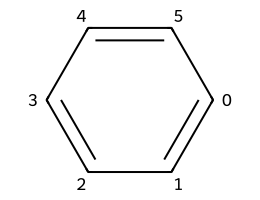
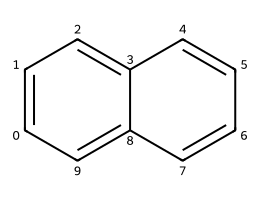
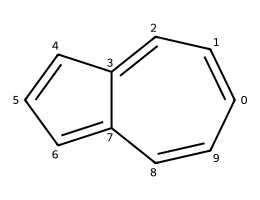
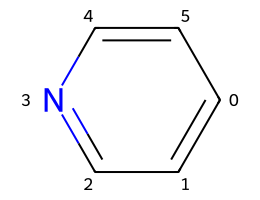
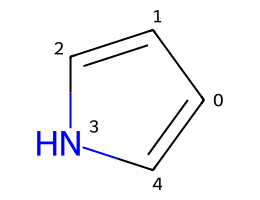
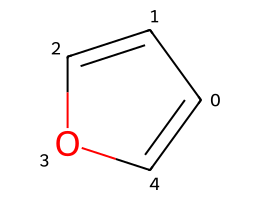
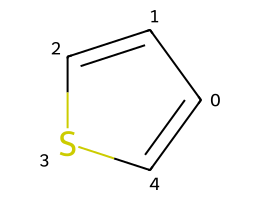
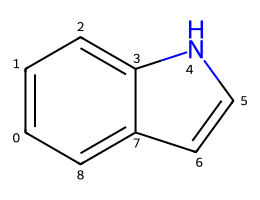
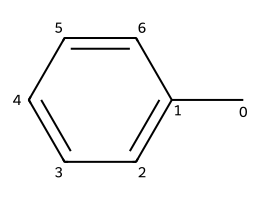
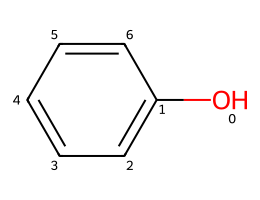
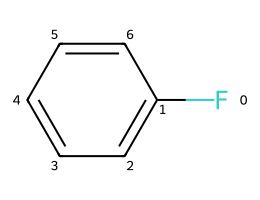
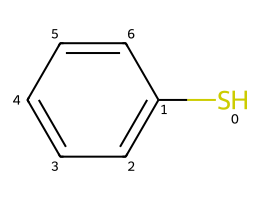
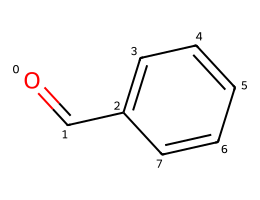
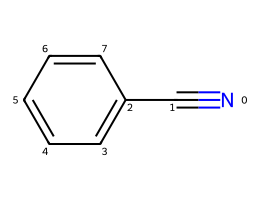
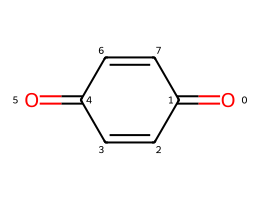
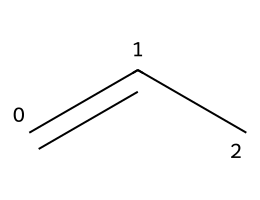
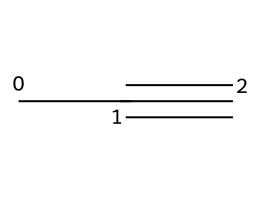
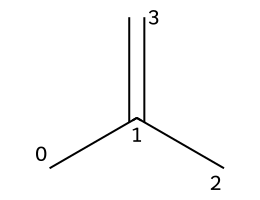
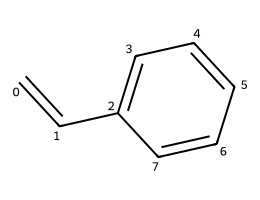
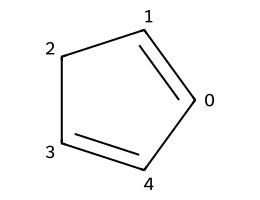
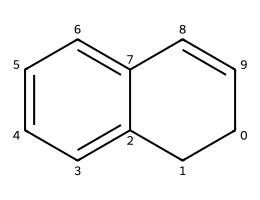
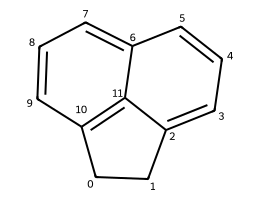
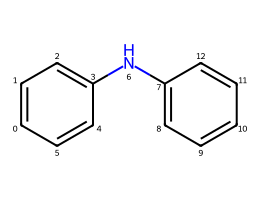
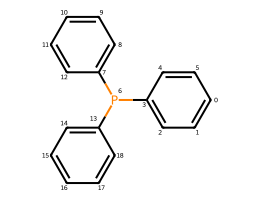
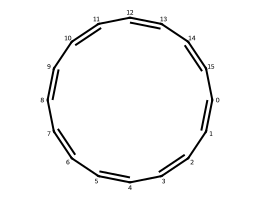
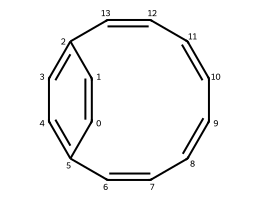
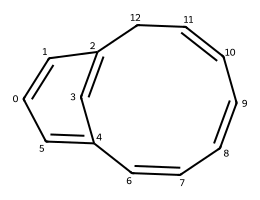
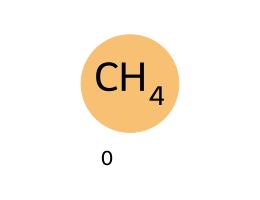
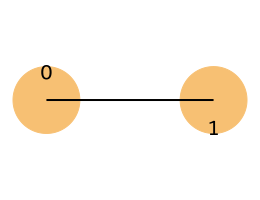
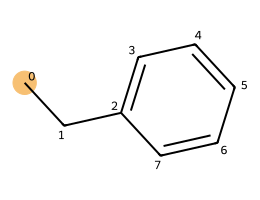
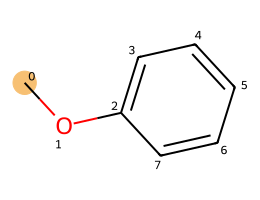
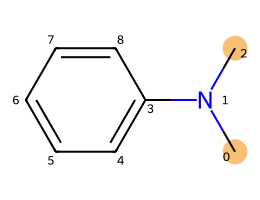
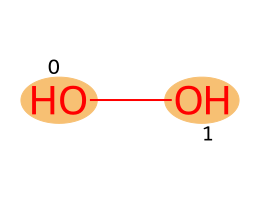
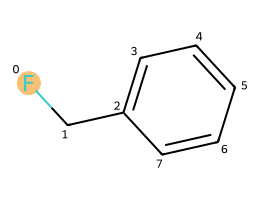
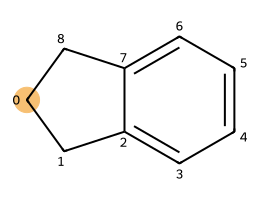
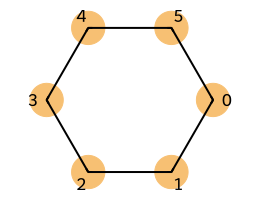
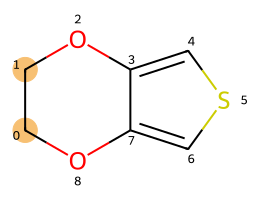
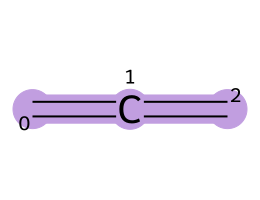
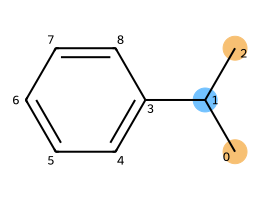
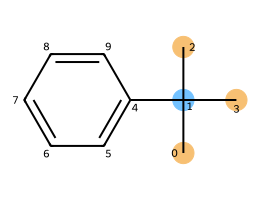
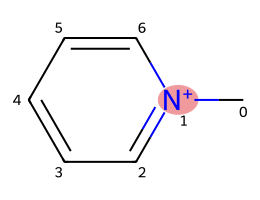
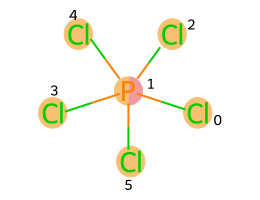
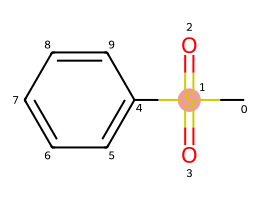
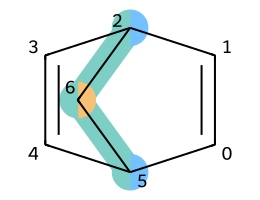
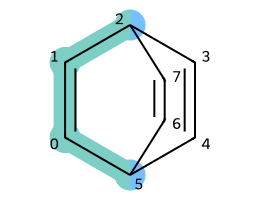
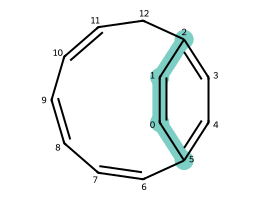
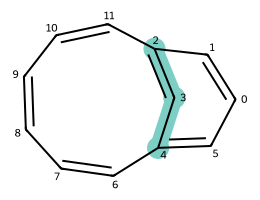
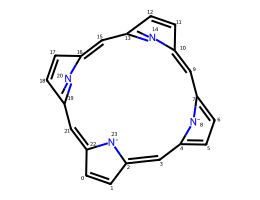
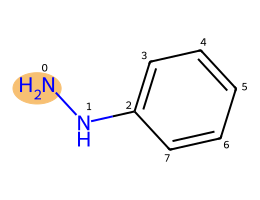
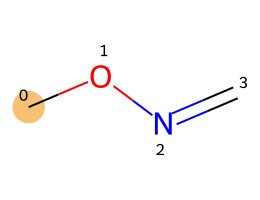
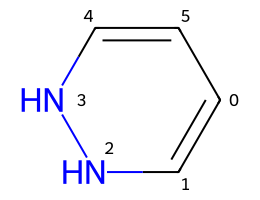
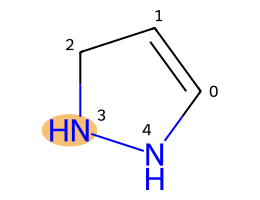
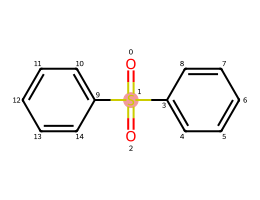
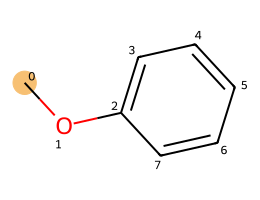
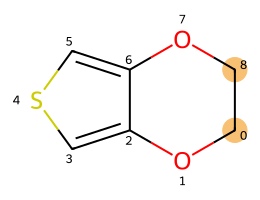
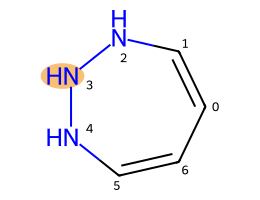
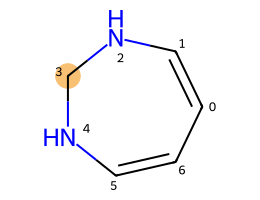
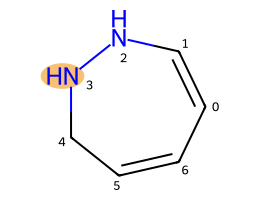
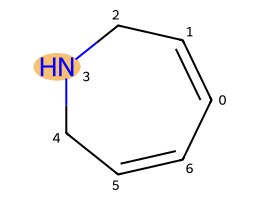
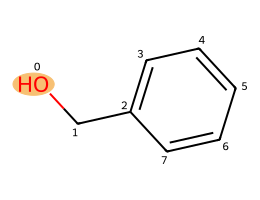
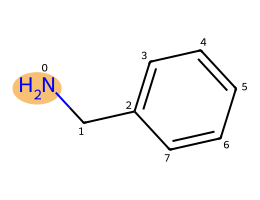
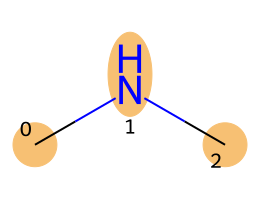
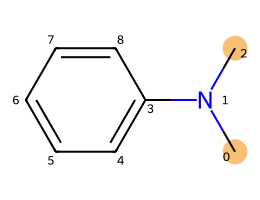
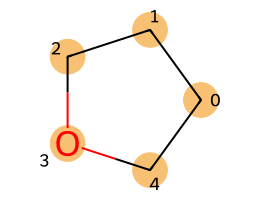
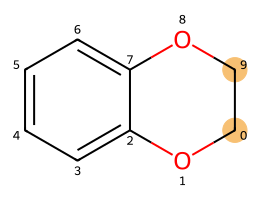
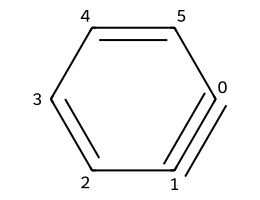
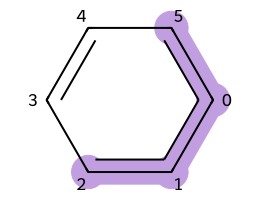
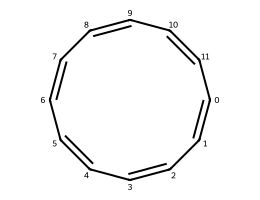
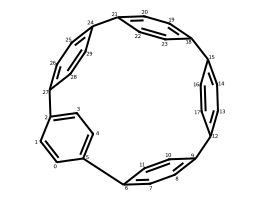
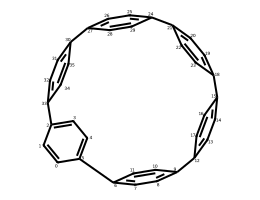
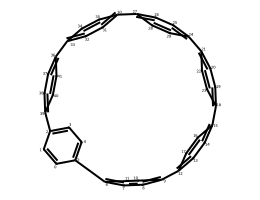
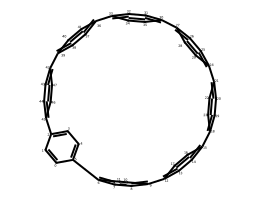
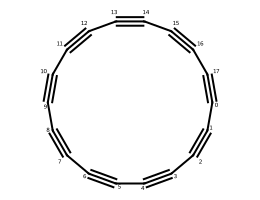
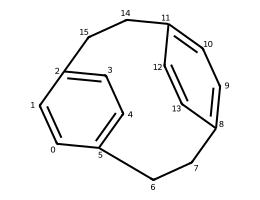
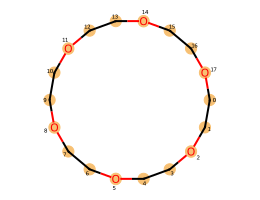
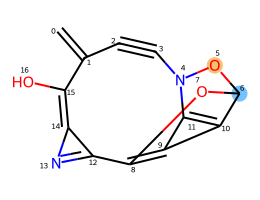
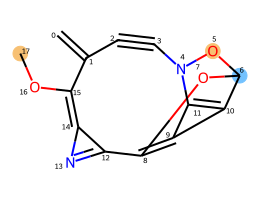
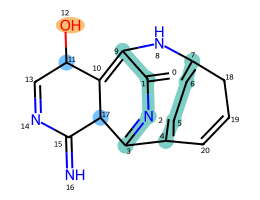
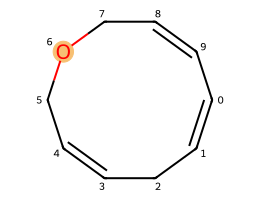
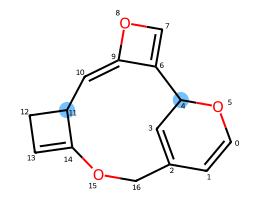
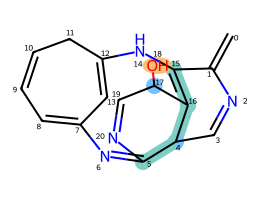
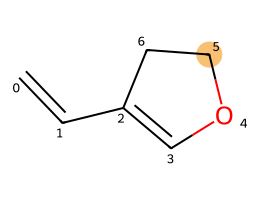
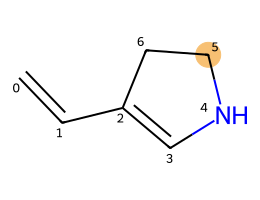
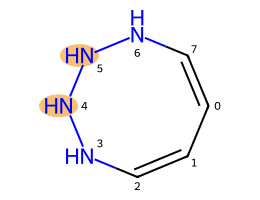
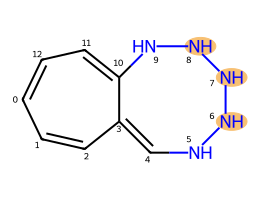
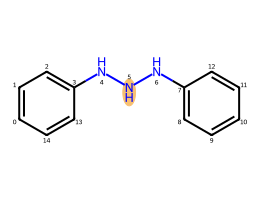
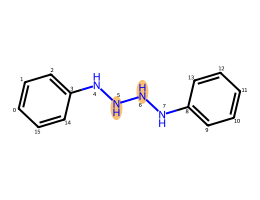
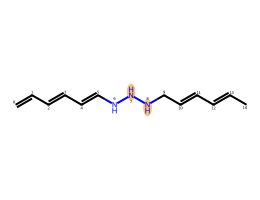
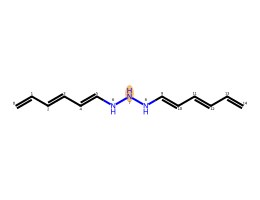
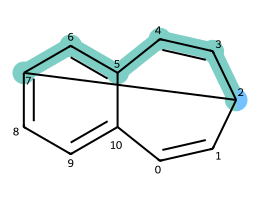
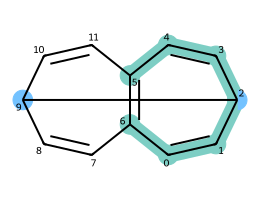
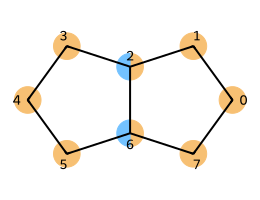

In [ ]:
display(REGLES.legend())
display(rv.show_list(bilan, REGLES, seulement_erreurs=False))

## Détail d'une molécule

Un dessin avec toutes les violations, puis un dessin par violation avec son message ; le tableau des violations ;
la matrice (électrons de valence sur la diagonale, ordres de liaison ailleurs ; H implicites avec les valences de
`VALENCES`, état `s` / `d` / `t`, degré), avec en couleur la diagonale des atomes en cause et les cases des liaisons
en cause, et la colonne `règles`.


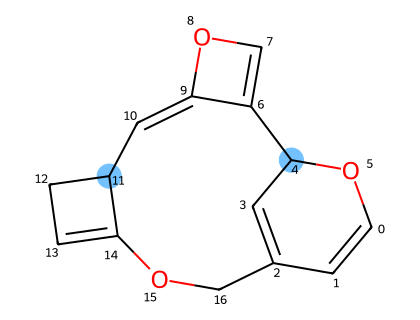


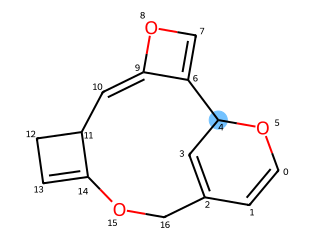
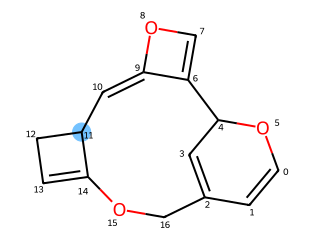

,règle,atomes,message
0,R3b,C4,C4 est un carbone s qui porte 3 atomes lourds ...
1,R3b,C11,C11 est un carbone s qui porte 3 atomes lourds...


,C0,C1,C2,C3,C4,O5,C6,C7,O8,C9,C10,C11,C12,C13,C14,O15,C16,H,état,degré,règles
C0,4,2,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,d,2,
C1,2,4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,d,2,
C2,0,1,4,2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,d,3,
C3,0,0,2,4,1,0,0,0,0,0,0,0,0,0,0,0,0,1,d,2,
C4,0,0,0,1,4,1,1,0,0,0,0,0,0,0,0,0,0,1,s,3,R3b
O5,1,0,0,0,1,6,0,0,0,0,0,0,0,0,0,0,0,0,s,2,
C6,0,0,0,0,1,0,4,2,0,1,0,0,0,0,0,0,0,0,d,3,
C7,0,0,0,0,0,0,2,4,1,0,0,0,0,0,0,0,0,1,d,2,
O8,0,0,0,0,0,0,0,1,6,1,0,0,0,0,0,0,0,0,s,2,
C9,0,0,0,0,0,0,1,0,1,4,2,0,0,0,0,0,0,0,d,3,


In [ ]:
SMILES = "C1=CC2=CC(O1)C1=COC1=CC1CC=C1OC2"

rv.show_rules(SMILES, REGLES)
display(rv.violations_table(SMILES, REGLES))
display(rv.matrix_table(SMILES, REGLES, VALENCES))

## Vitesse

Temps moyen par molécule (µs) sur `N_VITESSE` molécules : lecture du SMILES, construction du `GrapheV2` (matrice et
tableaux numpy), chaque règle, toutes ensemble, et pour comparaison les règles actuelles d'evomol
(`matrix_rules.all_violations`, graphe compris).

In [ ]:
N_VITESSE = 2000
lot_vitesse = rv.sample_chembl(N_VITESSE, seed=1, source="pi")
display(rv.timing(lot_vitesse, REGLES))

2000 molécules


,total (s),µs / molécule
étape,,
lecture du SMILES,0.525,262.5
GrapheV2,0.314,157.1
R1,0.007,3.6
R2,0.014,7.0
R3a,0.006,3.0
R3b,0.007,3.5
R4,0.120,60.1
toutes les règles,0.166,82.8
evomol (GrapheV1 + règles),0.229,114.3
